# Solar Power Generation Prediction and Performance Analysis Across Diverse Regions

## 1. Problem Statement

Solar energy operators and energy analysts need to estimate hourly solar power generation under different environmental conditions.

This project aims to develop a machine learning regression model to predict AC power output using weather, geographical and time-related features across four countries.

The model will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R-squared (R²).

## 2. Project Details

- Problem Type: Regression
- Target Variable: AC_Power
- Dataset: Solar Data from Diverse Regions
- Dataset Source: Kaggle
- Dataset Size: 35,136 records
- Number of Countries: 4
- Data Period: January to December 2024
- End Users: Solar energy analysts and plant operators

## 3. Project Objectives

1. Perform exploratory data analysis.
2. Identify and investigate data quality issues.
3. Perform numerical and categorical preprocessing.
4. Develop and compare multiple regression models.
5. Tune the best-performing model.
6. Evaluate model performance and analyze prediction errors.
7. Deploy the final model using Streamlit.

## Load Dataset

In [8]:
import pandas as pd
df=pd.read_csv(r"C:\Users\HP\Documents\Solar_Power_Generation_Prediction\data\solar data.csv")

## Data Inspection

In [14]:
df.head(2)

,Date,Time,DateTime,Country,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
0,2024-01-01,0,2024-01-01 00:00:00,Norway,0.0,0.0,-10.15,-3.33,0.039,1,1,0,145.722,145.722
1,2024-01-01,1,2024-01-01 01:00:00,Norway,0.0,0.0,-10.06,-3.50,0.014,1,1,1,145.722,291.444


In [15]:
df.tail(2)

,Date,Time,DateTime,Country,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
35134,2024-12-31,22,2024-12-31 22:00:00,Australia,0.0,0.0,8.36,13.61,0.017,31,12,22,490.155,3644722.485
35135,2024-12-31,23,2024-12-31 23:00:00,Australia,0.0,0.0,8.16,12.95,0.000,31,12,23,490.155,3645212.640


In [17]:
df.shape

(35136, 14)

In [16]:
df.columns

Index(['Date', 'Time', 'DateTime', 'Country', 'DC_Power', 'AC_Power',
       'Ambient_Temperature', 'Module_Temperature', 'Irradiation', 'Day',
       'Month', 'Hour', 'Daily_Yield', 'Total_Yield'],
      dtype='object')

In [18]:
df.dtypes

Date                    object
Time                     int64
DateTime                object
Country                 object
DC_Power               float64
AC_Power               float64
Ambient_Temperature    float64
Module_Temperature     float64
Irradiation            float64
Day                      int64
Month                    int64
Hour                     int64
Daily_Yield            float64
Total_Yield            float64
dtype: object

In [11]:
df.info

<bound method DataFrame.info of              Date  Time             DateTime    Country  DC_Power  AC_Power  \
0      2024-01-01     0  2024-01-01 00:00:00     Norway     0.000     0.000   
1      2024-01-01     1  2024-01-01 01:00:00     Norway     0.000     0.000   
2      2024-01-01     2  2024-01-01 02:00:00     Norway     0.000     0.000   
3      2024-01-01     3  2024-01-01 03:00:00     Norway     0.000     0.000   
4      2024-01-01     4  2024-01-01 04:00:00     Norway     0.000     0.000   
...           ...   ...                  ...        ...       ...       ...   
35131  2024-12-31    19  2024-12-31 19:00:00  Australia     9.771     8.896   
35132  2024-12-31    20  2024-12-31 20:00:00  Australia     0.000     0.000   
35133  2024-12-31    21  2024-12-31 21:00:00  Australia     0.000     0.000   
35134  2024-12-31    22  2024-12-31 22:00:00  Australia     0.000     0.000   
35135  2024-12-31    23  2024-12-31 23:00:00  Australia     0.000     0.000   

       Ambient_Temp

In [20]:
df.describe()

,Time,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
count,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,35136.000000,3.513600e+04
mean,11.500000,18.328791,16.597491,19.471019,24.475755,0.303354,15.756831,6.513661,11.500000,398.339796,1.756229e+06
std,6.922285,22.507191,20.414370,11.857084,11.886490,0.360226,8.811655,3.451283,6.922285,85.781465,1.050192e+06
min,0.000000,0.000000,0.000000,-11.480000,-7.910000,0.000000,1.000000,1.000000,0.000000,140.666000,1.457220e+02
25%,5.750000,0.000000,0.000000,13.297500,18.350000,0.000000,8.000000,4.000000,5.750000,359.825750,8.425283e+05
50%,11.500000,0.000000,0.000000,21.130000,26.225000,0.075500,16.000000,7.000000,11.500000,420.060000,1.770125e+06
75%,17.250000,36.568500,32.928250,28.360000,33.320000,0.603000,23.000000,10.000000,17.250000,458.513750,2.616968e+06
max,23.000000,83.478000,81.336000,39.360000,46.940000,1.214000,31.000000,12.000000,23.000000,520.186000,4.064366e+06


In [22]:
df.nunique()

Date                     366
Time                      24
DateTime                8784
Country                    4
DC_Power               15310
AC_Power               15069
Ambient_Temperature     4789
Module_Temperature      4940
Irradiation             1109
Day                       31
Month                     12
Hour                      24
Daily_Yield             1462
Total_Yield            35136
dtype: int64

## Data Quality Check

In [23]:
df.isnull().sum()

Date                   0
Time                   0
DateTime               0
Country                0
DC_Power               0
AC_Power               0
Ambient_Temperature    0
Module_Temperature     0
Irradiation            0
Day                    0
Month                  0
Hour                   0
Daily_Yield            0
Total_Yield            0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [26]:
numerical_col=df.select_dtypes(include=["int64","float64"]).columns
numerical_col

Index(['Time', 'DC_Power', 'AC_Power', 'Ambient_Temperature',
       'Module_Temperature', 'Irradiation', 'Day', 'Month', 'Hour',
       'Daily_Yield', 'Total_Yield'],
      dtype='object')

In [29]:
categorical_col=df.select_dtypes(include=["object","category"]).columns
categorical_col

Index(['Date', 'DateTime', 'Country'], dtype='object')

###### Now "Date" and "DateTime" columns are in objects instead of date time format.So we needed to convert object into date time so we can analyse time-based patterns

In [32]:
df["Date"]=pd.to_datetime(df["Date"])
df["DateTime"]=pd.to_datetime(df["DateTime"])

In [33]:
df.dtypes

Date                   datetime64[ns]
Time                            int64
DateTime               datetime64[ns]
Country                        object
DC_Power                      float64
AC_Power                      float64
Ambient_Temperature           float64
Module_Temperature            float64
Irradiation                   float64
Day                             int64
Month                           int64
Hour                            int64
Daily_Yield                   float64
Total_Yield                   float64
dtype: object

#### Negative values in each column

In [40]:
(df.select_dtypes(include="number")<0).sum()

Time                      0
DC_Power                  0
AC_Power                  0
Ambient_Temperature    3470
Module_Temperature     2342
Irradiation               0
Day                       0
Month                     0
Hour                      0
Daily_Yield               0
Total_Yield               0
dtype: int64

In [43]:
Q1=df.select_dtypes(include="number").quantile(0.25)
Q3=df.select_dtypes(include="number").quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outliers=((df.select_dtypes(include="number")<lower_bound) | (df.select_dtypes(include="number")>upper_bound)).sum()
outliers

Time                      0
DC_Power                  0
AC_Power                  0
Ambient_Temperature     838
Module_Temperature      863
Irradiation               0
Day                       0
Month                     0
Hour                      0
Daily_Yield            2304
Total_Yield               0
dtype: int64

## EDA

### Univariate Analysis

#### Target variable distribution

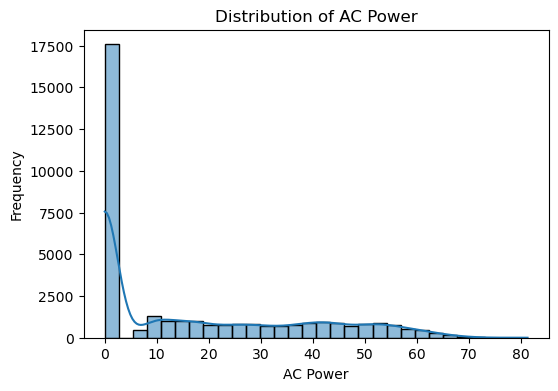

In [63]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
plt.figure(figsize=(6,4))
sns.histplot(df["AC_Power"],bins=30,kde=True)
plt.title("Distribution of AC Power")
plt.xlabel("AC Power")
plt.ylabel("Frequency")
plt.show()

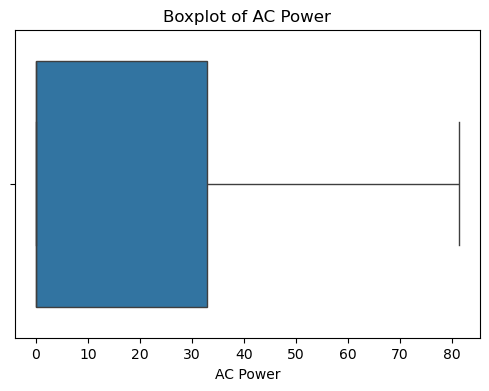

In [51]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df["AC_Power"])
plt.title("Boxplot of AC Power")
plt.xlabel("AC Power")
plt.show()

#### Other features distribution

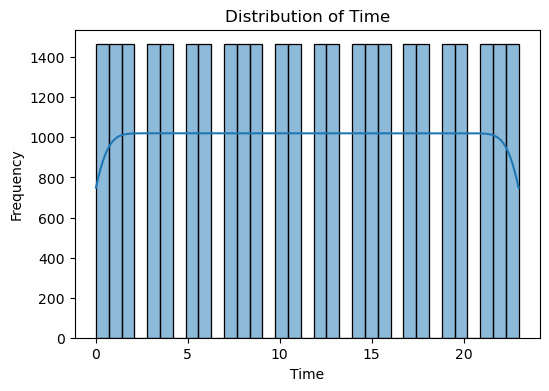

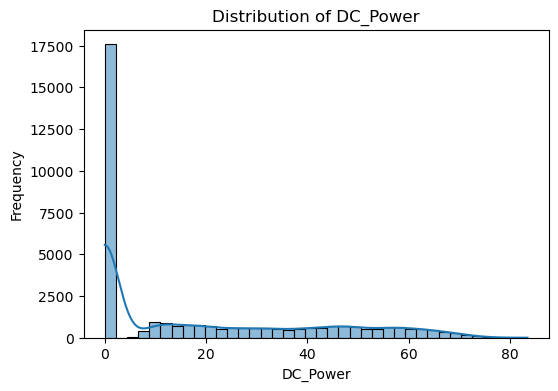

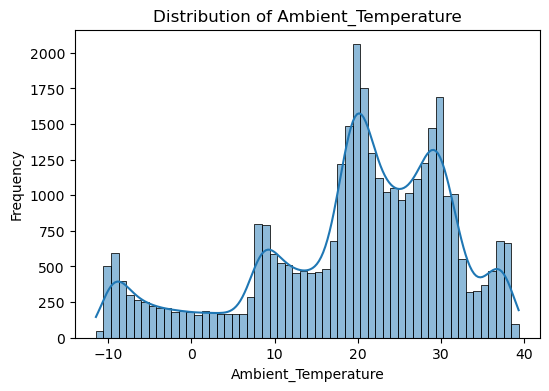

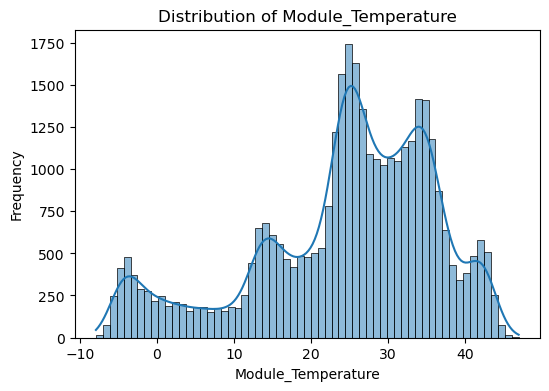

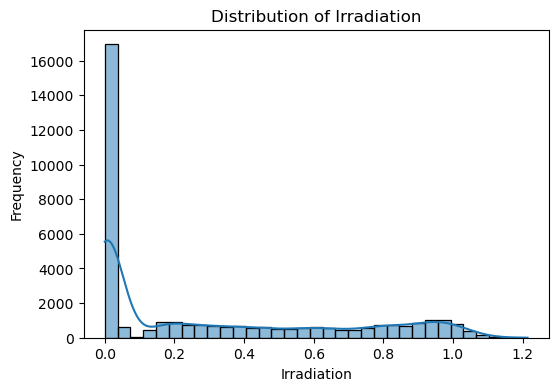

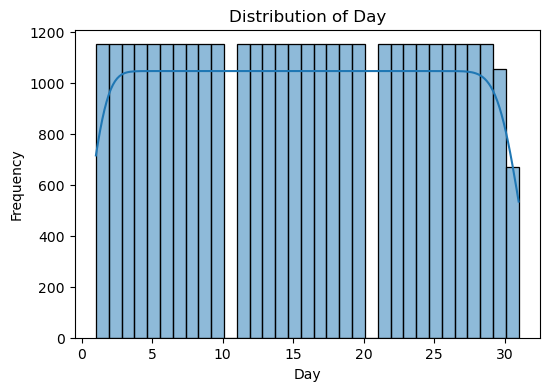

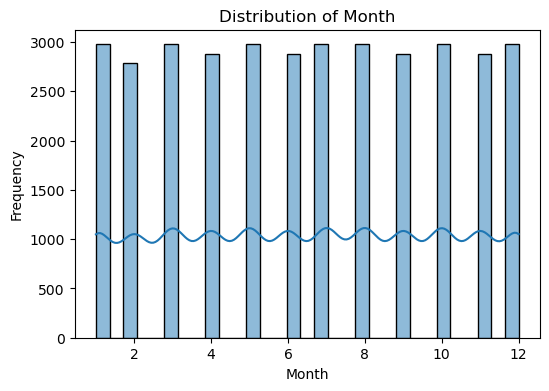

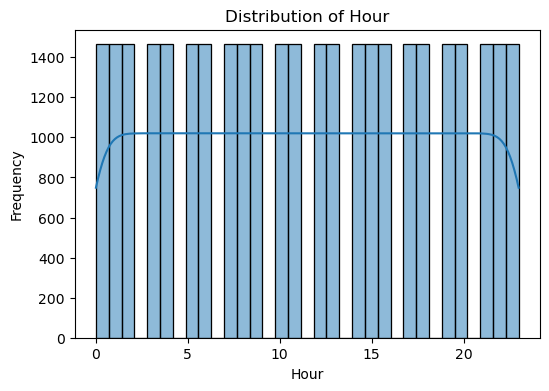

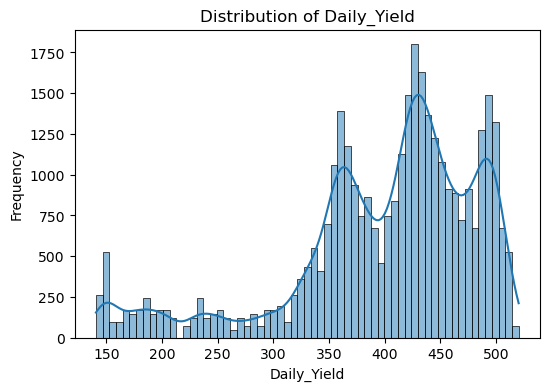

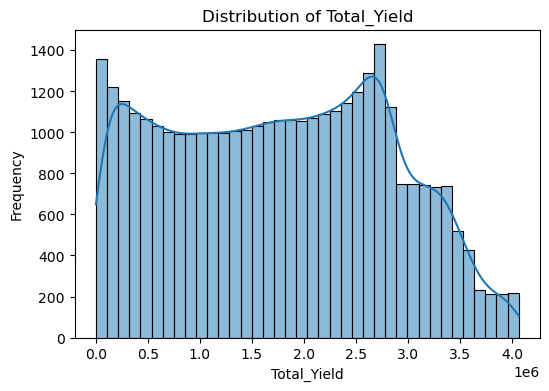

In [61]:
features=df.drop(columns=["AC_Power"])
numerical_features=features.select_dtypes(include="number")
for i in numerical_features.columns:
    plt.figure(figsize=(6,4))
    sns.histplot(features[i],kde=True)
    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.ylabel("Frequency")
    plt.show()

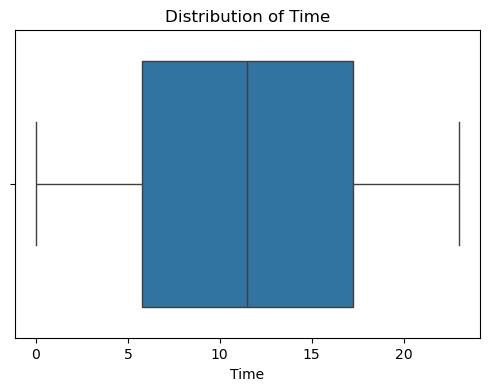

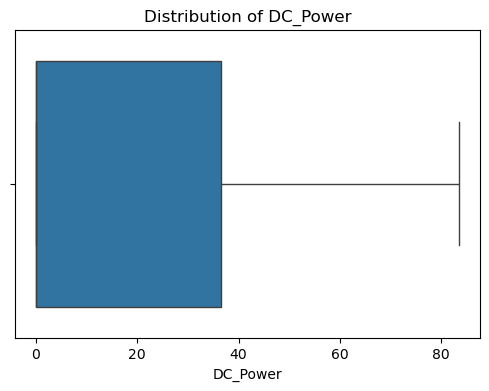

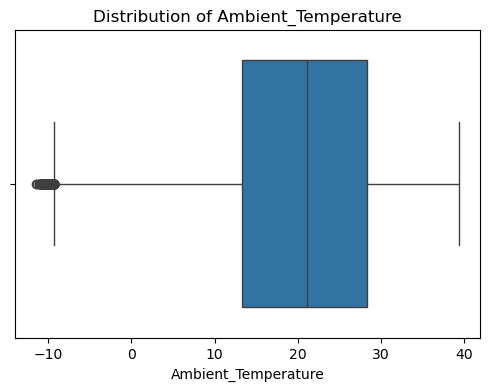

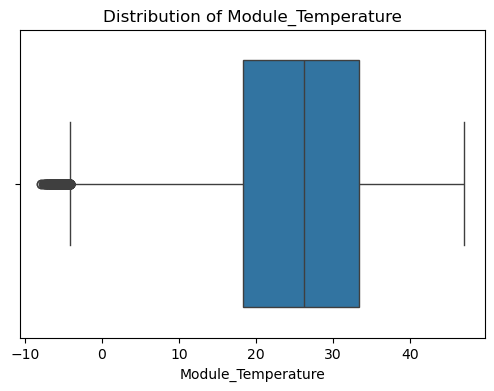

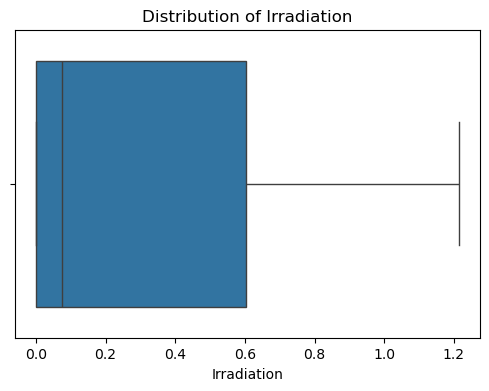

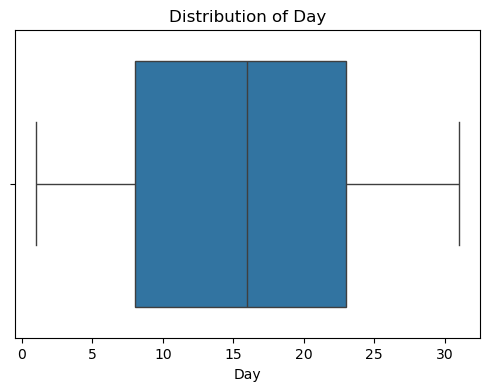

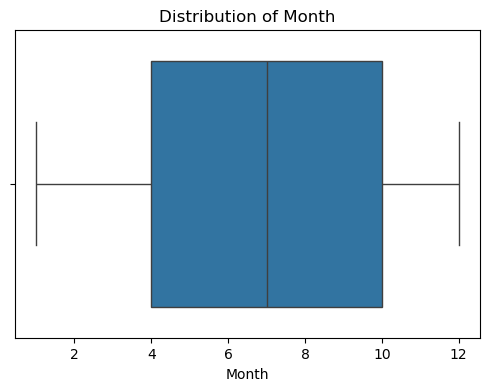

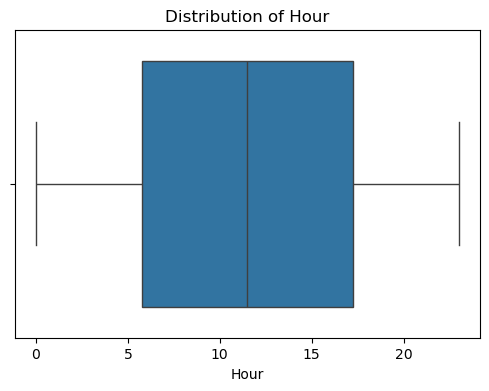

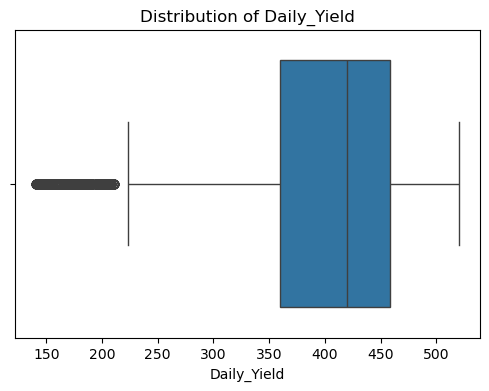

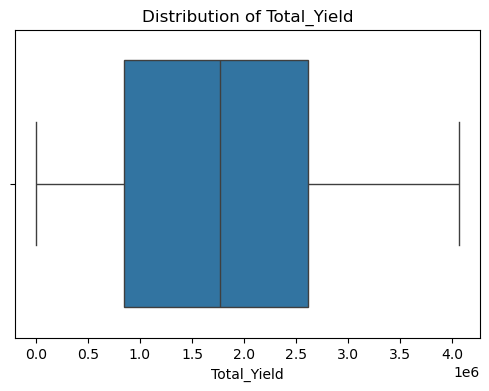

In [62]:
features=df.drop(columns=["AC_Power"])
numerical_features=features.select_dtypes(include="number")
for i in numerical_features.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=features[i])
    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.show()

#### Countplot for categorical features

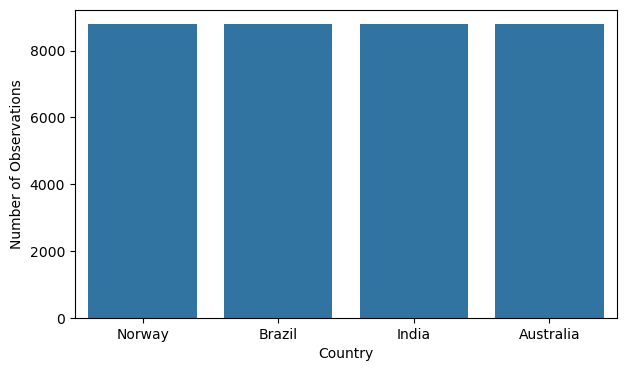

In [69]:
plt.figure(figsize=(7,4))
sns.countplot(x=df["Country"])
plt.ylabel("Number of Observations")
plt.show()